In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LassoCV

import matplotlib.pyplot as plt


# Data Preprocessing and Model Training

This notebook processes Malawi LSMS (Living Standards Measurement Survey) 2019-2020 data to create a consumption prediction model for poverty targeting.

**Pipeline:**
1. Load and clean survey data (consumption, assets, housing, ...)
2. Merge into a single household-level dataset
3. Train a LASSO model to predict consumption from observable characteristics

**Data source:** The survey data can be downloaded from the LSMS program [here](https://microdata.worldbank.org/catalog/3818/study-description).

**Output:** `survey_2019_2020.csv` — processed dataset with predictions


In [3]:
root = '/Users/miekochun/Desktop/DSC Capstone/Malawi/data/raw/MWI_2019_IHS-V_v06_M_Stata/'


## Preprocessing 


### Consumption data


In [4]:
# Read consumption data, get HHID + Total nominal annual consumption per household 
cons = pd.read_stata(root + 'ihs5_consumption_aggregate.dta')
cons = cons[['case_id', 'expagg']]
cons.columns = ['hhid', 'Consumption']

# Drop any households with missing ID or missing consumption
cons['hhid'] = cons['hhid'].apply(lambda x: np.nan if x == '' else x) 
cons = cons.dropna(how='any')

# Convert to MWK per USD, World Bank average of 2019 and 2020
exchange_rate = 747.535  
cons['Consumption'] = cons['Consumption']/exchange_rate

print('Households with consumption data: %i' % len(cons))

Households with consumption data: 11434


### Asset data


In [5]:
# Assets from L file
# Get asset data from asset module
assets_L = pd.read_stata(root + 'HH_MOD_L.dta')
assets_L = assets_L[['case_id', 'hh_l02', 'hh_l03']]
assets_L['case_id'] = assets_L['case_id'].apply(lambda x: np.nan if x == '' else x)

# Drop households missing ID and duplicate records
assets_L = assets_L.dropna(subset=['case_id'])
assets_L = assets_L.drop_duplicates(subset=['case_id', 'hh_l02'])

# Convert count to own (1) or not (0)
assets_L['hh_l03'] = assets_L['hh_l03'].apply(lambda x: 1 if x > 0 else 0).astype(int)

assets_L[assets_L['case_id'].isin(['101011000014', '101011000023', '101011000040'])]

# Pivot to per-household dataset
assets_L = assets_L.pivot(columns=['hh_l02'], index=['case_id'])
assets_L.columns = [str(c[1]) for c in assets_L.columns]
assets_L['hhid'] = assets_L.index
assets_L.index = range(len(assets_L))
assets_L = assets_L.fillna(0)

# Assets from M file
# Get asset data from asset module
assets_M = pd.read_stata(root + 'HH_MOD_M.dta')
assets_M = assets_M[['case_id', 'hh_m0b', 'hh_m00']]
assets_M['case_id'] = assets_M['case_id'].apply(lambda x: np.nan if x == '' else x)

# Drop households missing ID and duplicate records
assets_M = assets_M.dropna(subset=['case_id'])
assets_M = assets_M.drop_duplicates(subset=['case_id', 'hh_m0b'])

# Convert Yes/No to own (1) or not (0)
assets_M['hh_m00'] = assets_M['hh_m00'].apply(lambda x: 1 if str(x).strip().lower() == 'yes' else 0)

assets_M[assets_M['case_id'].isin(['101011000014', '101011000023', '101011000040'])]

# Pivot to per-household dataset
assets_M = assets_M.pivot(columns=['hh_m0b'], index=['case_id'])
assets_M.columns = [str(c[1]).title() for c in assets_M.columns]
assets_M['hhid'] = assets_M.index
assets_M.index = range(len(assets_M))
assets_M = assets_M.fillna(0)

assets = assets_L.merge(assets_M, how='outer', on='hhid')
asset_cols = [c for c in assets.columns if c != 'hhid']
assets[asset_cols] = assets[asset_cols].fillna(0).astype(int)

# Combine generator from assets and farm surveys
assets['Generator'] = assets[['Generator_x', 'Generator_y']].max(axis=1)
assets = assets.drop(columns=['Generator_x', 'Generator_y'])

print('Households with asset data: %i' % len(assets))

assets.columns


Households with asset data: 11434


Index(['Mortar/pestle (mtondo)', 'Bed', 'Table', 'Chair', 'Fan',
       'Air conditioner', 'Radio ('wireless')', 'Tape or CD/DVD player; HiFi',
       'Television', 'VCR', 'Sewing machine', 'Kerosene/paraffin stove',
       'Electric or gas stove; hot plate', 'Refrigerator', 'Washing machine',
       'Bicycle', 'Motorcycle / Scooter', 'Car', 'Mini-bus', 'Lorry',
       'Beer-brewing drum', 'Upholstered chair, sofa set',
       'Coffee table (for sitting room)', 'Cupboard, drawers, bureau',
       'Lantern (paraffin)', 'Desk', 'Clock', 'Iron (for pressing clothes)',
       'Computer equipment & accessories', 'Sattelite dish', 'Solar panel',
       'Electric Kettle', 'Radio with flash drive/micro CD', 'hhid',
       'Hand Hoe', 'Slasher', 'Axe', 'Sprayer', 'Panga Knife', 'Sickle',
       'Treadle Pump', 'Watering Can', 'Ox Cart', 'Ox Plough', 'Tractor',
       'Tractor Plough', 'Ridger', 'Cultivator', 'Motorised Pump',
       'Grain Mill', 'Other', 'Chicken House', 'Livestock Kraal',
   

### Housing data


In [6]:
# Get housing data from housing module
housing = pd.read_stata(root + 'HH_MOD_F.dta', convert_categoricals=False)
housing = housing[['case_id', 'hh_f01', 'hh_f10', 'hh_f07', 'hh_f08', 'hh_f09',
                   'hh_f43', 'hh_f11', 'hh_f12', 'hh_f19', 'hh_f36', 'hh_f41', 'hh_f34', 'hh_f48']]
colnames = ['hhid', 'Ownership status', 'Rooms', 'Walls', 'Roof', 'Floor', 'Garbage', 
            'Lighting fuel', 'Cooking fuel', 'Electricity', 'Drinking water', 'Toilet', 'Cell phones', 'Bank account']
housing.columns = colnames

# Drop households missing IDs, no other column has missingness
housing['hhid'] = housing['hhid'].apply(lambda x: np.nan if x == '' else x)
housing = housing.dropna()

print('Households with housing data: %i' % len(housing))


Households with housing data: 11434


### Demographic data


In [7]:
# Get demographic data from individual roster module 
demographics = pd.read_stata(root + 'HH_MOD_B.dta', convert_categoricals=False)
demographics = demographics[['case_id', 'hh_b04', 'hh_b03', 'hh_b05a', 'hh_b24']]
demographics.columns = ['hhid', 'hhh', 'gender', 'age', 'married']

# Add missing category to marrital status
demographics['married'] = demographics['married'].fillna(0)

# Drop any rows missing ID
demographics['hhid'] = demographics['hhid'].apply(lambda x: np.nan if x == '' else x)
demographics = demographics.dropna(subset=['hhid'])

# Create dataframe of household head data
hhh = demographics[demographics['hhh'] == 1].copy()
hhh = hhh[['hhid', 'gender', 'age', 'married']]
hhh.columns = ['hhid', 'HHH gender', 'HHH age', 'HHH married']

# Create dataframe with number of children in household
children = demographics[demographics['age'] < 5].copy()
children = children[['hhid', 'gender']].groupby('hhid', as_index=False).agg('count')\
    .rename({'gender':'Children'}, axis=1)

# Create dataframe with other misc demographic data -- region, number of members
geo = pd.read_stata(root + 'ihs5_consumption_aggregate.dta', convert_categoricals=False)
geo = geo[['case_id', 'region', 'hhsize']]
geo.columns = ['hhid', 'region', 'hh_size']

# Merge all demographic data together
demographics = geo.merge(hhh, on='hhid', how='left').merge(children, on='hhid', how='left')
demographics['Children'] = demographics['Children'].fillna(0)
demographics = demographics.dropna()

print('Households with demographic data: %i' % len(demographics))



Households with demographic data: 11434


### Education data


In [8]:
# Get IDs for just household heads
hhh = pd.read_stata(root + 'HH_MOD_B.dta', convert_categoricals=False)
hhh = hhh[['case_id', 'PID', 'hh_b04']]
hhh.columns = ['hhid', 'pid', 'hhh']
hhh = hhh[hhh['hhh'] == 1][['hhid', 'pid']]

# Read education data from individual roster module 
education = pd.read_stata(root + 'HH_MOD_C.dta', convert_categoricals=False)
education = education[['case_id', 'PID', 'hh_c05_1', 'hh_c06', 'hh_c08', 'hh_c24']]
education.columns = ['hhid', 'pid', 'literate', 'school', 'level_school', 'use_computer']

# Merge education data to IDs to get education data for just household heads
education = education.merge(hhh, on=['hhid', 'pid'], how='inner').drop('pid', axis=1)
 
# Recode literacy, education, computer variables 
education['literate'] = education['literate'].apply(lambda x: 1 if x == 1 else 0).astype(int)
education['level_school'] = education.apply(lambda row: -1 if row['school'] == 2 else 
                                            row['level_school'], axis=1)
education['use_computer'] = education['use_computer'].apply(lambda x: 1 if x == 1 else 0).astype(int)

education = education.drop('school', axis=1)
education['level_school'] = education['level_school'].fillna(-1)

print('Households with education data: %i' % len(education))

education


Households with education data: 11434


,hhid,literate,level_school,use_computer
0,101011000014,1,8.0,0
1,101011000023,1,3.0,0
2,101011000040,1,10.0,0
3,101011000071,1,8.0,0
4,101011000095,1,7.0,0
...,...,...,...,...
11429,315538160177,1,8.0,0
11430,315538160189,1,7.0,0
11431,315538160190,1,12.0,1
11432,315538160235,1,11.0,0


### Merge all data together


In [9]:
# Combine together all dataframes (HH need to have consumption data, can have other data missing)
df = cons.merge(demographics, on='hhid', how='left').merge(housing, on='hhid', how='left')\
    .merge(assets, on='hhid', how='left').merge(education, on='hhid', how='left')\
    .dropna()\
    .drop_duplicates(subset=['hhid'])

# Get outcome and feature variables
outcome = 'Consumption'
x_vars = [c for c in df.columns if c not in ['hhid', outcome]]

# Define type for each feature variable manually 
x_var_types = {
    # demographics
    'region': 'cat', 'hh_size': 'int', 'HHH gender': 'bin',
    'HHH age': 'int', 'HHH married': 'cat', 'Children': 'int',
    # housing 
    'Ownership status': 'cat', 'Rooms': 'int', 'Walls': 'cat', 'Roof': 'cat',
    'Floor': 'cat', 'Garbage': 'cat', 'Lighting fuel': 'cat', 'Cooking fuel': 'cat',
    'Electricity': 'bin', 'Drinking water': 'cat', 'Toilet': 'cat',
    'Cell phones': 'int', 'Bank account': 'bin',
    # education
    'literate': 'bin', 'level_school': 'cat', 'use_computer': 'bin',
}

# every asset column is an integer 0/1 flag
for c in assets.columns:
    if c != 'hhid':
        x_var_types[c] = 'int' 

for var in x_vars:
    
    # Check binary variables for having exactly 2 values, and convert values to 0 and 1
    if x_var_types[var] == 'bin':
        if len(df[var].unique()) != 2:
            print('Error: Unique values in column ' + var + ' not equal to 2')
        if 2 in df[var].unique():
            df[var] = df[var] - 1
            
    # Winsorize then scale continuous variables, and drop any that have 100% missingness or are constant
    elif x_var_types[var] == 'int':
        cutoff = np.percentile(df[var], 99)
        df[var] = df[var].apply(lambda x: cutoff if x > cutoff else x)
        df[var] = (df[var] - df[var].min())/(df[var].max() - df[var].min())
        if df[var].isnull().mean() == 1:
            df = df.drop(var, axis=1)

# Combine any categories in categorical variables with <1% of observations into an "other" category
# and one hot encode
cat_vars = [v for v in x_vars if x_var_types[v] == 'cat']
for cat_var in cat_vars:
    to_remove = []
    grouped = pd.DataFrame(df.groupby(cat_var).count()['hhid']/len(df))
    for value, share in grouped.iterrows():
        if share['hhid'] < 0.01:
            to_remove.append(value)
    df[cat_var] = df[cat_var].apply(lambda x: 9999 if x in to_remove else x)
df = pd.get_dummies(df, columns=cat_vars, drop_first=True)

df.to_csv('survey_2019_2020.csv', index=False)
print('Households in final dataset: %i' % len(df))


Households in final dataset: 11434


## Data Visualizations

In [10]:
df

,hhid,Consumption,hh_size,HHH gender,HHH age,Children,Rooms,Electricity,Cell phones,Bank account,...,level_school_4.0,level_school_5.0,level_school_6.0,level_school_7.0,level_school_8.0,level_school_9.0,level_school_10.0,level_school_11.0,level_school_12.0,level_school_9999.0
0,101011000014,546.093567,0.333333,0,0.366197,0.5,0.500000,1,0.25,1,...,False,False,False,False,True,False,False,False,False,False
1,101011000023,925.415710,0.333333,1,0.563380,0.0,0.500000,1,0.00,0,...,False,False,False,False,False,False,False,False,False,False
2,101011000040,511.802979,0.333333,1,0.140845,1.0,0.500000,1,0.25,0,...,False,False,False,False,False,False,True,False,False,False
3,101011000071,3093.129150,0.444444,0,0.507042,0.0,0.666667,1,0.25,0,...,False,False,False,False,True,False,False,False,False,False
4,101011000095,1252.487427,0.444444,0,0.253521,0.0,0.666667,1,0.00,1,...,False,False,False,True,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11429,315538160177,1677.757935,0.222222,1,0.084507,0.5,0.500000,1,0.00,1,...,False,False,False,False,True,False,False,False,False,False
11430,315538160189,1814.178955,0.222222,0,0.154930,0.0,0.333333,0,0.00,1,...,False,False,False,True,False,False,False,False,False,False
11431,315538160190,1142.894653,0.000000,0,0.436620,0.0,0.166667,0,0.25,0,...,False,False,False,False,False,False,False,False,True,False
11432,315538160235,2149.931641,0.222222,0,0.183099,0.0,0.500000,0,0.50,0,...,False,False,False,False,False,False,False,True,False,False


In [11]:
pd.set_option("display.max_columns", None)
display(df)

,hhid,Consumption,hh_size,HHH gender,HHH age,Children,Rooms,Electricity,Cell phones,Bank account,Mortar/pestle (mtondo),Bed,Table,Chair,Fan,Radio ('wireless'),Tape or CD/DVD player; HiFi,Television,Sewing machine,Electric or gas stove; hot plate,Refrigerator,Bicycle,Motorcycle / Scooter,Car,Beer-brewing drum,"Upholstered chair, sofa set",Coffee table (for sitting room),"Cupboard, drawers, bureau",Clock,Iron (for pressing clothes),Computer equipment & accessories,Sattelite dish,Solar panel,Electric Kettle,Radio with flash drive/micro CD,Hand Hoe,Slasher,Axe,Sprayer,Panga Knife,Sickle,Watering Can,Ox Cart,Ox Plough,Grain Mill,Other,Chicken House,Livestock Kraal,Poultry Kraal,Granary,Barn,Pig Sty,literate,use_computer,region_2,region_3,HHH married_2.0,HHH married_3.0,HHH married_4.0,HHH married_5.0,HHH married_6.0,Ownership status_3,Ownership status_4,Ownership status_6,Ownership status_9999,Walls_3,Walls_4,Walls_5,Walls_6,Walls_9999,Roof_2,Roof_9999,Floor_2,Floor_3,Floor_9999,Garbage_2,Garbage_3,Garbage_4,Garbage_5,Garbage_6,Lighting fuel_5,Lighting fuel_7,Lighting fuel_8,Lighting fuel_9,Lighting fuel_9999,Cooking fuel_2,Cooking fuel_4,Cooking fuel_6,Cooking fuel_7,Cooking fuel_9999,Drinking water_2,Drinking water_3,Drinking water_5,Drinking water_7,Drinking water_8,Drinking water_10,Drinking water_17,Drinking water_9999,Toilet_6,Toilet_7,Toilet_8,Toilet_9,Toilet_12,Toilet_9999,level_school_1.0,level_school_2.0,level_school_3.0,level_school_4.0,level_school_5.0,level_school_6.0,level_school_7.0,level_school_8.0,level_school_9.0,level_school_10.0,level_school_11.0,level_school_12.0,level_school_9999.0
0,101011000014,546.093567,0.333333,0,0.366197,0.5,0.500000,1,0.25,1,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0,False,False,True,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
1,101011000023,925.415710,0.333333,1,0.563380,0.0,0.500000,1,0.00,0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,True,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
2,101011000040,511.802979,0.333333,1,0.140845,1.0,0.500000,1,0.25,0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,0,False,False,False,True,False,False,False,False,True,False,False,False,False,True,False,False,True,False,True,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False
3,101011000071,3093.129150,0.444444,0,0.507042,0.0,0.666667,1,0.25,0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1,0,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True,False,True,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,

/var/folders/q2/cgg1l8w16k1g8gr2znypm6sr0000gn/T/ipykernel_87412/2373382601.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


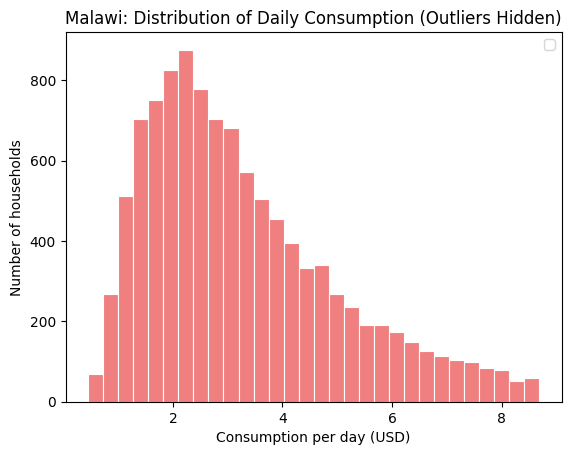

In [12]:
data = df['Consumption'].dropna() / 365

q1, q3 = data.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
plot_data = data[data <= upper]          

plt.hist(plot_data, bins=30, edgecolor='white', linewidth=0.8, color='lightcoral')
plt.title("Malawi: Distribution of Daily Consumption (Outliers Hidden)")
plt.xlabel("Consumption per day (USD)")
plt.ylabel("Number of households")
plt.legend()
plt.show()

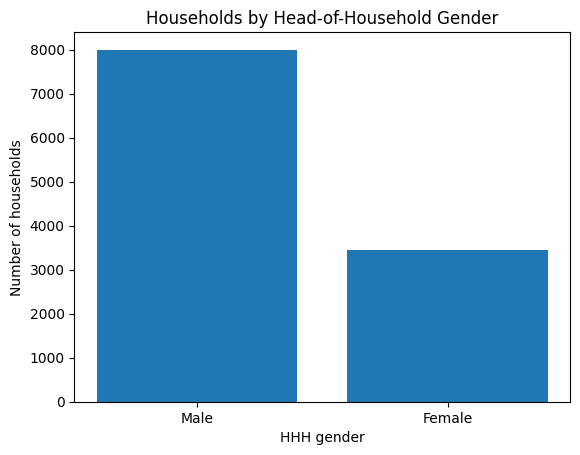

In [13]:
counts = df['HHH gender'].value_counts().sort_index()   

plt.bar(['Male', 'Female'], counts.values)
plt.title("Households by Head-of-Household Gender")
plt.xlabel("HHH gender")
plt.ylabel("Number of households")
plt.show()

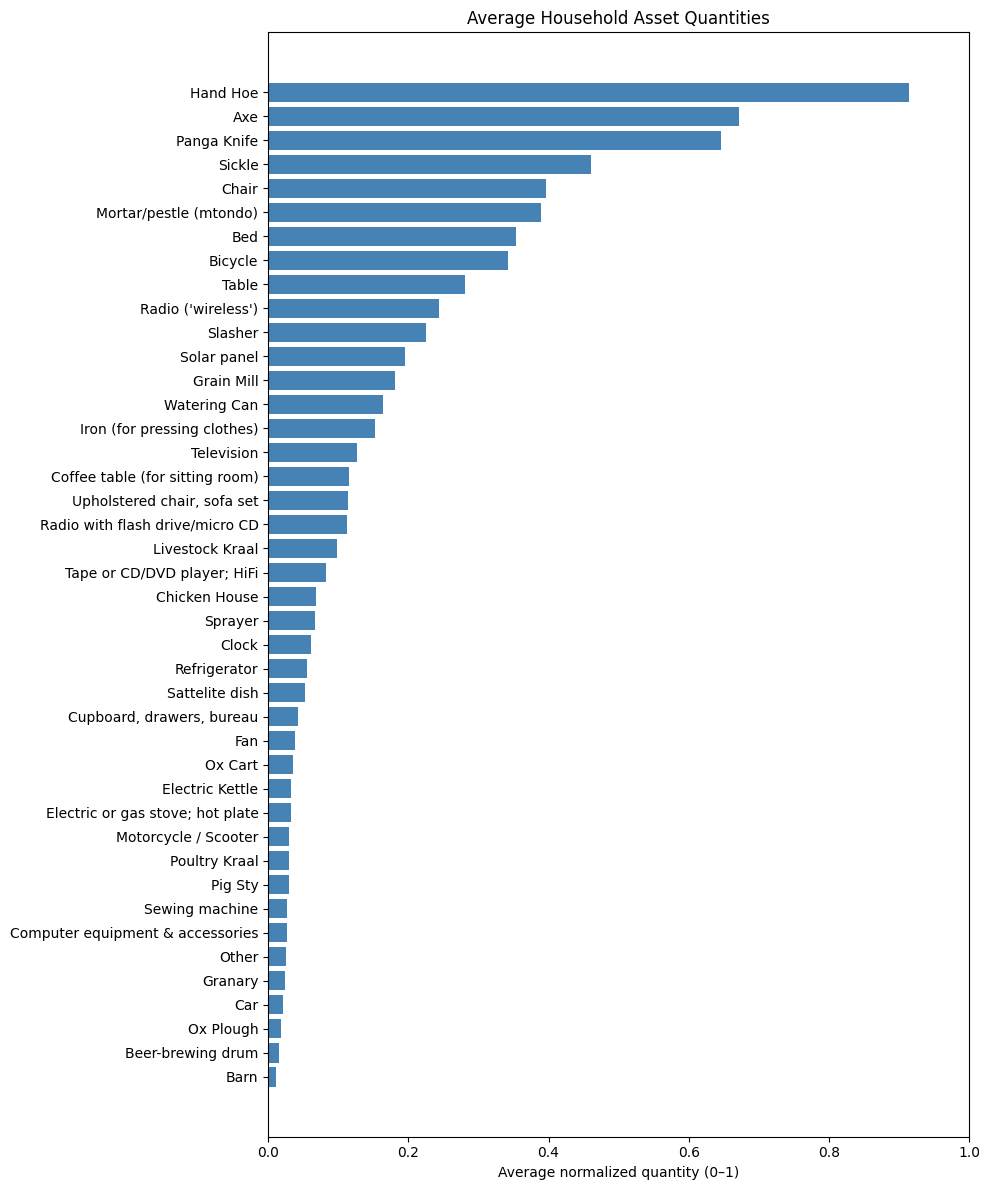

In [14]:
asset_cols = [c for c in assets.columns if c != 'hhid' and c in df.columns]

avg_assets = df[asset_cols].mean().sort_values()

plt.figure(figsize=(10, 12))
plt.barh(avg_assets.index, avg_assets.values, color='steelblue')
plt.xlabel('Average normalized quantity (0–1)')
plt.title('Average Household Asset Quantities')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

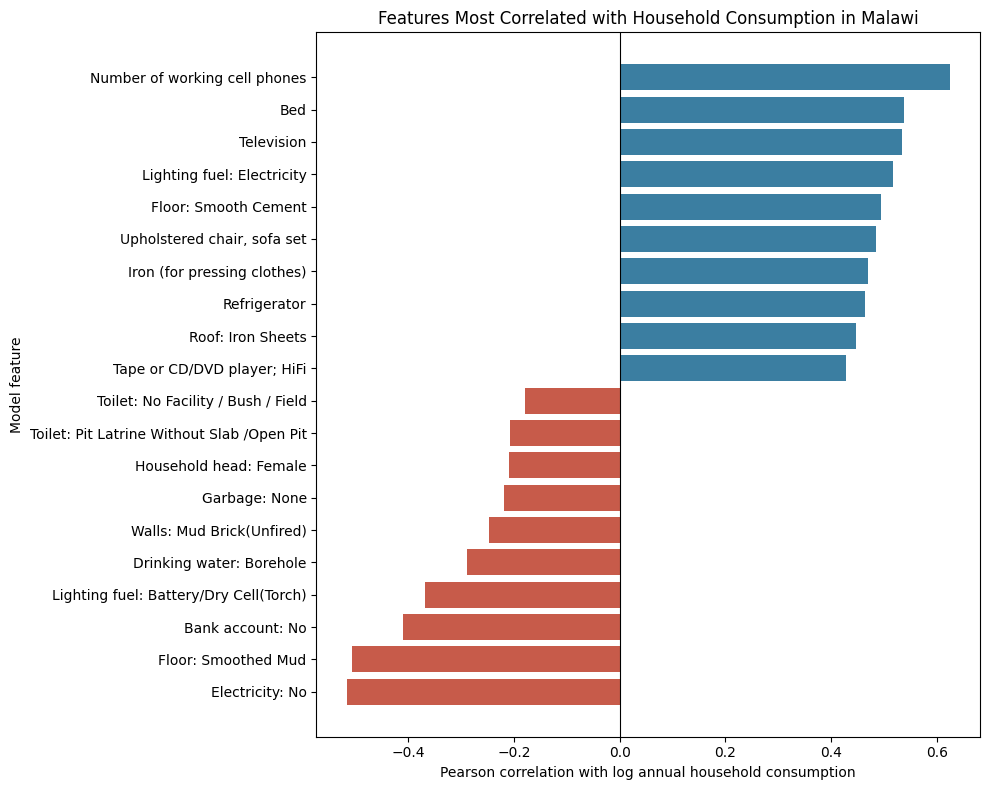

In [15]:
# Pearson correlations with log annual household consumption
# The log transform reduces the influence of a small number of very high-consumption households.
log_consumption = np.log(df['Consumption'])
feature_cols = [c for c in df.columns if c not in ['hhid', 'Consumption']]
correlations = df[feature_cols].corrwith(log_consumption).dropna()

# Show the strongest relationships in each direction.
top_negative = correlations.nsmallest(10)
top_positive = correlations.nlargest(10)
top_correlations = pd.concat([top_negative, top_positive]).sort_values()

# Replace one-hot-encoded survey codes (for example, Floor_3) with their labels.
category_sources = {
    'region': ('ihs5_consumption_aggregate.dta', 'region'),
    'HHH married': ('HH_MOD_B.dta', 'hh_b24'),
    'Ownership status': ('HH_MOD_F.dta', 'hh_f01'),
    'Walls': ('HH_MOD_F.dta', 'hh_f07'),
    'Roof': ('HH_MOD_F.dta', 'hh_f08'),
    'Floor': ('HH_MOD_F.dta', 'hh_f09'),
    'Garbage': ('HH_MOD_F.dta', 'hh_f43'),
    'Lighting fuel': ('HH_MOD_F.dta', 'hh_f11'),
    'Cooking fuel': ('HH_MOD_F.dta', 'hh_f12'),
    'Drinking water': ('HH_MOD_F.dta', 'hh_f36'),
    'Toilet': ('HH_MOD_F.dta', 'hh_f41'),
    'level_school': ('HH_MOD_C.dta', 'hh_c08')
}

category_labels = {}
for feature, (filename, variable) in category_sources.items():
    codes = pd.read_stata(root + filename, convert_categoricals=False)[variable]
    labels = pd.read_stata(root + filename)[variable]
    label_df = pd.DataFrame({'code': codes, 'label': labels}).dropna().drop_duplicates('code')
    category_labels[feature] = dict(zip(label_df['code'], label_df['label'].astype(str)))

binary_labels = {
    'HHH gender': 'Household head: Female',
    'Electricity': 'Electricity: No',
    'Bank account': 'Bank account: No',
    'literate': 'Household head is literate',
    'use_computer': 'Household head has used a computer',
    'Cell phones': 'Number of working cell phones'
}

def display_feature_name(feature):
    if feature in binary_labels:
        return binary_labels[feature]
    for category, labels in category_labels.items():
        prefix = category + '_'
        if feature.startswith(prefix):
            try:
                code = float(feature[len(prefix):])
                label = labels.get(code, labels.get(int(code), feature))
                return f'{category}: {label.title()}'
            except ValueError:
                return feature
    return feature

top_correlations.index = [display_feature_name(feature) for feature in top_correlations.index]

colors = ['#C75B4A' if value < 0 else '#3B7EA1' for value in top_correlations]
plt.figure(figsize=(10, 8))
plt.barh(top_correlations.index, top_correlations.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('Pearson correlation with log annual household consumption')
plt.ylabel('Model feature')
plt.title('Features Most Correlated with Household Consumption in Malawi')
plt.tight_layout()
plt.show()

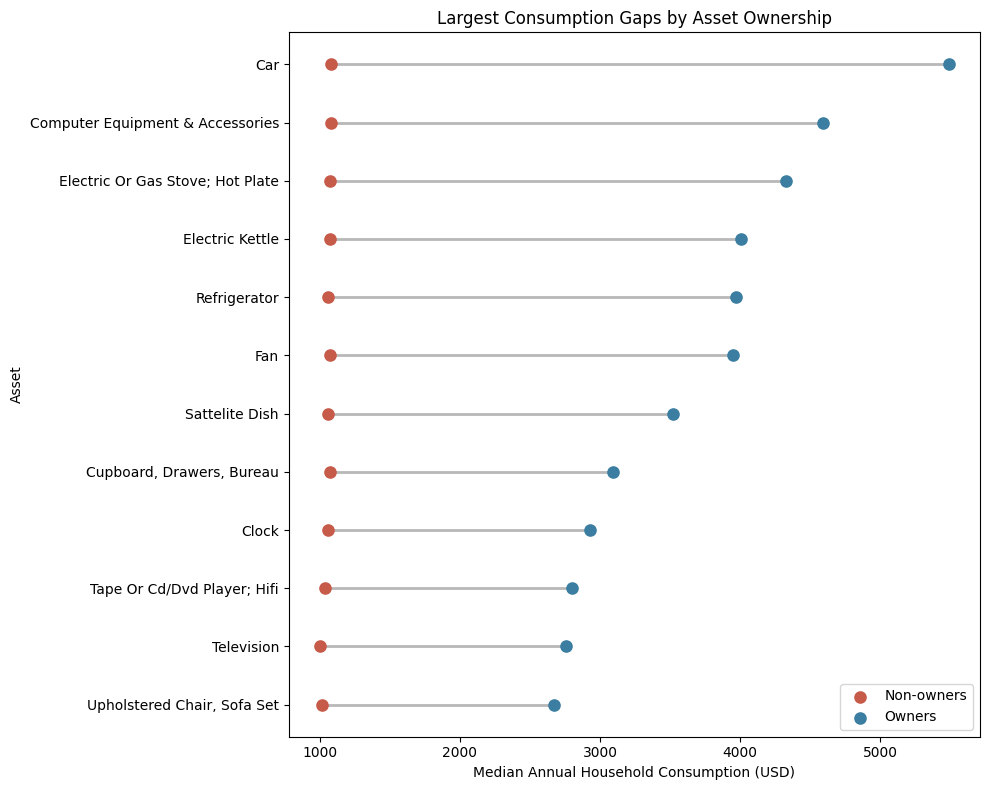

In [16]:
# Compare median household consumption for asset owners and non-owners.
asset_gaps = []
for asset in asset_cols:
    owner_consumption = df.loc[df[asset] == 1, 'Consumption']
    non_owner_consumption = df.loc[df[asset] == 0, 'Consumption']
    # Exclude extremely rare assets so the comparison is stable.
    if len(owner_consumption) >= 100 and len(non_owner_consumption) >= 100:
        asset_gaps.append({
            'Asset': asset,
            'Owners': owner_consumption.median(),
            'Non-owners': non_owner_consumption.median(),
            'Log median gap': np.log(owner_consumption.median()) - np.log(non_owner_consumption.median())
        })

asset_gaps = pd.DataFrame(asset_gaps)
top_asset_gaps = asset_gaps.loc[asset_gaps['Log median gap'].abs().nlargest(12).index].sort_values('Owners')
y_positions = np.arange(len(top_asset_gaps))

plt.figure(figsize=(10, 8))
plt.hlines(y=y_positions, xmin=top_asset_gaps['Non-owners'], xmax=top_asset_gaps['Owners'], color='#B8B8B8', linewidth=2)
plt.scatter(top_asset_gaps['Non-owners'], y_positions, color='#C75B4A', s=65, label='Non-owners', zorder=3)
plt.scatter(top_asset_gaps['Owners'], y_positions, color='#3B7EA1', s=65, label='Owners', zorder=3)
plt.yticks(y_positions, top_asset_gaps['Asset'].str.title())
plt.xlabel('Median Annual Household Consumption (USD)')
plt.ylabel('Asset')
plt.title('Largest Consumption Gaps by Asset Ownership')
plt.legend()
plt.tight_layout()
plt.show()

## Model Training


In [17]:
def train_consumption_model(random_state=0):
    """Train LASSO model to predict consumption from survey features.
    
    Returns:
        DataFrame with columns 'y_test' (actual) and 'yhat_test' (predicted),
        both in USD PPP.
    """
    df = pd.read_csv('survey_2019_2020.csv')
    
    outcome = 'Consumption'
    extras = ['hhid']
    
    # Train/test split, log-transform consumption
    train, test = train_test_split(df, random_state=random_state, test_size=0.25)
    x_train = train.drop([outcome] + extras, axis=1)
    y_train = np.log(train[outcome])
    x_test = test.drop([outcome] + extras, axis=1)
    y_test = np.log(test[outcome])
    
    # Train LASSO with cross-validated alpha
    model = LassoCV(fit_intercept=True, random_state=random_state)
    model.fit(x_train, y_train)
    yhat_test = model.predict(x_test)
    
    # Back-transform to USD PPP
    results = pd.DataFrame({
        'y_test': np.exp(y_test),
        'yhat_test': np.exp(yhat_test)
    })
    
    return results


In [18]:
from pathlib import Path

output_dir = Path("data/seed")

for seed in range(10):
    results = train_consumption_model(random_state=seed)
    results.rename(
        columns={"y_test": "ground_truth", "yhat_test": "predictions"}
    ).to_csv(output_dir / f"seed_{seed}.csv", index=False)

In [19]:
from sklearn.metrics import r2_score, mean_absolute_error

results = train_consumption_model()
y, yhat = results['y_test'], results['yhat_test']

print('R² (log scale):', r2_score(np.log(y), np.log(yhat)))
print('Correlation (USD):', np.corrcoef(y, yhat)[0, 1])
print('Median abs % error:', (abs(yhat - y) / y).median())
print('MAE (USD/yr):', mean_absolute_error(y, yhat))
print(y.mean())
print(yhat.mean())

R² (log scale): 0.6762731101003493
Correlation (USD): 0.8499451022840842
Median abs % error: 0.24990283068803867
MAE (USD/yr): 408.5420356267565
1441.2593199020637
1352.771299596936
